<a href="https://colab.research.google.com/github/miguelcuero-ai/Fisica-computacional-2026-2/blob/main/Taller%207/Taller_7_FC_Arreglos_IDN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/carlospi2000/Notes_on_Computational_Physics/blob/main/07.Arrays_integrals_derivatives/Arreglos_int_deriv_ESTUDIANTES-7.ipynb)

# Semana 7 — Arreglos: integración y derivación numérica

**Física Computacional — 106018C** · Lenguaje: **Fortran y Python**

Las teoria de esta semana icluye series de Taylor, interpolación de Lagrange, órdenes de error y extrapolación de Richardson. Este notebook contiene los programas que producen los ejemplos de esas láminas, dos ejercicios de calentamiento y, al final, el **Taller 7**.

La semana se reparte entre los dos lenguajes: los **arreglos** se presentan en Fortran y en Python, lado a lado; la **integración** se programa en Fortran y la **derivación** en Python.

**Objetivos de la sesión**

1. Declarar arreglos en Fortran (tamaño fijo, límites propios y memoria dinámica con `allocatable`) y operar sobre secciones completas.
2. Distinguir listas y arreglos de NumPy en Python, y traducir secciones entre los dos lenguajes (base 1 frente a base 0).
3. Pasar arreglos a procedimientos de un módulo con forma asumida.
4. Integrar con las reglas del trapecio y de Simpson, y verificar su orden de convergencia.
5. Construir la tabla de Romberg por extrapolación de Richardson.
6. Derivar con diferencias finitas de distinto orden y encontrar el paso óptimo frente al error de redondeo.

<div style="border-left: 5px solid #162A54; background-color: #EEF1F7; padding: 10px 14px; margin: 8px 0;">

**Alcance.** Esta semana se usan arreglos de una y dos dimensiones como almacenamiento de datos. Las operaciones de álgebra lineal con matrices (productos, sistemas de ecuaciones) se ven en el Capítulo 5.

</div>

In [39]:
# Preparación: bibliotecas de Python y colores del curso
import numpy as np
import matplotlib.pyplot as plt

AZUL, DORADO, ROJO, VERDE, GRIS = "#162A54", "#C9972C", "#B02A20", "#2E7D32", "#7F7F7F"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Comprobación del compilador de Fortran
!gfortran --version | head -n 1

GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0


## 1. Arreglos en Fortran

Hasta la Semana 6 cada variable guardaba un solo número. Una función muestreada en una malla, $y_i = f(x_i)$ con $i = 1, \dots, n$, son $n$ números que se procesan juntos: se suman, se restan entre vecinos o se pasan completos a un procedimiento. Un **arreglo** es una variable con nombre que guarda una colección de valores del mismo tipo, y cada valor se identifica por su **índice**.

### 1.1 Declaración, límites y memoria dinámica

| Declaración | Índices válidos | Cuándo se fija el tamaño |
|---|---|---|
| `real(dp) :: y(5)` | 1, 2, 3, 4, 5 | al compilar |
| `real(dp) :: t(0:4)` | 0, 1, 2, 3, 4 | al compilar |
| `real(dp), allocatable :: x(:)` y luego `allocate(x(n))` | 1, …, n | al ejecutar |

- Por defecto, el primer índice en Fortran es **1**. Los límites se pueden elegir: `t(0:4)` tiene cinco elementos, del 0 al 4.
- Un arreglo `allocatable` no ocupa memoria hasta que se ejecuta `allocate`. Su tamaño puede depender de un valor leído durante la ejecución: esta es la **memoria dinámica** del título del capítulo.
- `size(y)` da el número de elementos; `lbound(y, 1)` y `ubound(y, 1)` dan el primer y el último índice de la dimensión 1.

### 1.2 Operaciones sobre el arreglo completo y secciones

| Expresión | Significado |
|---|---|
| `y = 0.0_dp` | asigna el mismo valor a todos los elementos |
| `y = sin(x)` | aplica la función elemento por elemento |
| `y(2:n-1)` | sección: elementos 2 a $n-1$ (ambos incluidos) |
| `y(2:n-1:2)` | sección con paso 2: elementos 2, 4, 6, … |
| `sum(y(2:n-1))` | suma de los elementos de la sección |
| `x = [( (i-1)*h, i = 1, n )]` | constructor con ciclo implícito |

El programa siguiente usa todo lo anterior. Lee $n$ desde el teclado, construye una malla de $n$ puntos en $[0, \pi]$ y suma secciones de $\sin x_i$.

In [40]:
%%writefile arreglos_basicos.f90
! ============================================================
! Programa:  arreglos_basicos
! Propósito: declarar arreglos de tamaño fijo, con límites
!            propios y dinámicos, y operar sobre secciones.
! Entrada:   n, número de puntos de la malla (teclado)
! Salida:    en pantalla
! ============================================================
program arreglos_basicos
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  real(dp), parameter :: pi = 4*atan(1.0_dp)
  real(dp) :: fijo(5)                    ! tamaño fijo, índices 1..5
  real(dp) :: tabla(0:4)                 ! límites propios, índices 0..4
  real(dp), allocatable :: x(:), y(:)    ! tamaño decidido al ejecutar
  integer :: n, i
  real(dp) :: h

  ! --- Arreglo de tamaño fijo: asignación elemento por elemento
  do i = 1, 5
     fijo(i) = real(i, dp)**2
  end do
  print '(a,5f6.1)', 'fijo  = ', fijo
  print '(a,i2,a,i2,a,i2)', 'fijo:  size =', size(fijo), &
        '   lbound =', lbound(fijo, 1), '   ubound =', ubound(fijo, 1)

  ! --- Arreglo con límites propios
  tabla = 0.0_dp                          ! asignación a todo el arreglo
  print '(a,i2,a,i2,a,i2)', 'tabla: size =', size(tabla), &
        '   lbound =', lbound(tabla, 1), '   ubound =', ubound(tabla, 1)

  ! --- Arreglo dinámico: n se conoce solo al ejecutar
  read *, n
  allocate(x(n), y(n))
  h = pi/(n - 1)
  x = [( (i - 1)*h, i = 1, n )]           ! malla uniforme en [0, pi]
  y = sin(x)                              ! función elemental sobre todo el arreglo

  print '(/,a,i3,a)', 'Malla de ', n, ' puntos en [0, pi]'
  print '(a,f10.6)', 'y(1)                        =', y(1)
  print '(a,f10.6)', 'y(n)                        =', y(n)
  print '(a,f10.6)', 'sum(y)                      =', sum(y)
  print '(a,f10.6)', 'sum(y(2:n-1))   interiores  =', sum(y(2:n-1))
  print '(a,f10.6)', 'sum(y(2:n-1:2)) índices 2,4 =', sum(y(2:n-1:2))
  print '(a,f10.6)', 'sum(y(3:n-2:2)) índices 3,5 =', sum(y(3:n-2:2))

  deallocate(x, y)                        ! libera la memoria
end program arreglos_basicos

Writing arreglos_basicos.f90


In [41]:
!gfortran -o arreglos_basicos arreglos_basicos.f90 && echo 11 | ./arreglos_basicos

fijo  =    1.0   4.0   9.0  16.0  25.0
fijo:  size = 5   lbound = 1   ubound = 5
tabla: size = 5   lbound = 0   ubound = 4

Malla de  11 puntos en [0, pi]
y(1)                        =  0.000000
y(n)                        =  0.000000
sum(y)                      =  6.313752
sum(y(2:n-1))   interiores  =  6.313752
sum(y(2:n-1:2)) índices 2,4 =  3.236068
sum(y(3:n-2:2)) índices 3,5 =  3.077684


Con $n = 11$, las secciones `y(2:10:2)` y `y(3:9:2)` separan los puntos interiores en dos grupos alternados: índices 2, 4, 6, 8, 10 y 3, 5, 7, 9. Esa separación es exactamente la que pide la regla de Simpson (sección 3.3), que da pesos distintos a cada grupo.

<div style="border-left: 5px solid #2E7D32; background-color: #EAF5EA; padding: 10px 14px; margin: 8px 0;">

**Consejo.** Libere con `deallocate` todo arreglo que ya no se use, y compruebe con `allocated(x)` antes de volver a reservarlo: ejecutar `allocate` sobre un arreglo que ya está reservado detiene el programa.

</div>

### 1.3 Índices fuera de los límites

Fortran no comprueba por defecto que un índice esté dentro de los límites declarados. Leer `y(6)` en un arreglo de cinco elementos no produce error: el programa lee lo que haya en esa posición de memoria.

In [42]:
%%writefile fuera_de_limites.f90
! ============================================================
! Programa:  fuera_de_limites
! Propósito: mostrar el efecto de leer fuera de los límites.
! Entrada:   m, último índice que se imprime (teclado)
! Salida:    en pantalla
! ============================================================
program fuera_de_limites
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  real(dp), allocatable :: y(:)
  integer :: i, m

  allocate(y(5))
  y = [( real(i, dp), i = 1, 5 )]
  read *, m                    ! se ejecutará con m = 6: un índice de más
  do i = 1, m
     print '(a,i1,a,es12.4)', 'y(', i, ') = ', y(i)
  end do
end program fuera_de_limites

Writing fuera_de_limites.f90


In [43]:
print("Sin comprobación de límites:")
!gfortran -o fuera_de_limites fuera_de_limites.f90 && echo 6 | ./fuera_de_limites
print("\nCon -fcheck=bounds:")
!gfortran -fcheck=bounds -o fuera_de_limites fuera_de_limites.f90 && echo 6 | ./fuera_de_limites 2>&1 | head -n 8

Sin comprobación de límites:
y(1) =   1.0000E+00
y(2) =   2.0000E+00
y(3) =   3.0000E+00
y(4) =   4.0000E+00
y(5) =   5.0000E+00
y(6) =   1.5860-321

Con -fcheck=bounds:
y(1) =   1.0000E+00
y(2) =   2.0000E+00
y(3) =   3.0000E+00
y(4) =   4.0000E+00
y(5) =   5.0000E+00
At line 17 of file fuera_de_limites.f90
Fortran runtime error: Index '6' of dimension 1 of array 'y' above upper bound of 5



<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**Evite** confiar en que el programa avise. Sin `-fcheck=bounds`, `y(6)` imprime un número sin sentido y el programa continúa: el error pasa a los resultados sin que nada lo indique. Compile con `gfortran -fcheck=bounds` mientras desarrolla; el programa se detiene en la primera lectura fuera de los límites e indica el índice y el arreglo.

</div>

### 1.4 Arreglos como argumentos de procedimientos

Un procedimiento de un módulo puede recibir un arreglo sin conocer su tamaño. El argumento se declara con **forma asumida**, `x(:)`, y dentro del procedimiento `size(x)` da el tamaño del arreglo que se pasó. Como en la Semana 6, el procedimiento va en un módulo: así el compilador conoce la forma de los argumentos y verifica cada llamada.

In [44]:
%%writefile modulo_malla.f90
! ============================================================
! Módulo:    modulo_malla
! Propósito: procedimientos que reciben arreglos con forma asumida.
! ============================================================
module modulo_malla
  implicit none
  integer, parameter :: dp = kind(1.0d0)
contains

  ! ----------------------------------------------------------
  ! malla_uniforme: llena x con puntos equiespaciados en [a, b]
  ! Entradas: a, b, extremos del intervalo
  ! Salida:   x, malla (su tamaño lo decide quien llama)
  ! ----------------------------------------------------------
  subroutine malla_uniforme(a, b, x)
    real(dp), intent(in)  :: a, b
    real(dp), intent(out) :: x(:)          ! forma asumida
    integer :: i, n
    n = size(x)
    x = [( a + (i - 1)*(b - a)/(n - 1), i = 1, n )]
  end subroutine malla_uniforme

  ! ----------------------------------------------------------
  ! informar_limites: muestra los límites que ve el procedimiento
  ! Entradas: t_defecto, declarado (:); t_cero, declarado (0:)
  ! Salida:   ninguna (imprime)
  ! ----------------------------------------------------------
  subroutine informar_limites(t_defecto, t_cero)
    real(dp), intent(in) :: t_defecto(:), t_cero(0:)
    print '(a,i2,a,i2)', '  declarado (:)  -> lbound =', lbound(t_defecto, 1), &
          '   ubound =', ubound(t_defecto, 1)
    print '(a,i2,a,i2)', '  declarado (0:) -> lbound =', lbound(t_cero, 1), &
          '   ubound =', ubound(t_cero, 1)
  end subroutine informar_limites

end module modulo_malla

Writing modulo_malla.f90


In [45]:
%%writefile usa_malla.f90
! ============================================================
! Programa:  usa_malla
! Propósito: llamar procedimientos que reciben arreglos.
! Salida:    en pantalla
! ============================================================
program usa_malla
  use modulo_malla, only: dp, malla_uniforme, informar_limites
  implicit none
  real(dp), allocatable :: x(:)
  real(dp) :: r(0:4)

  allocate(x(6))
  call malla_uniforme(0.0_dp, 1.0_dp, x)    ! el tamaño viaja con el arreglo
  print '(a,6f6.2)', 'x = ', x

  r = 0.0_dp
  print '(/,a)', 'Arreglo real declarado r(0:4); dentro del procedimiento:'
  call informar_limites(r, r)
end program usa_malla

Writing usa_malla.f90


In [46]:
!gfortran -o usa_malla modulo_malla.f90 usa_malla.f90 && ./usa_malla

x =   0.00  0.20  0.40  0.60  0.80  1.00

Arreglo real declarado r(0:4); dentro del procedimiento:
  declarado (:)  -> lbound = 1   ubound = 5
  declarado (0:) -> lbound = 0   ubound = 4


<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**Evite** suponer que un argumento de forma asumida conserva los límites del arreglo original. Dentro del procedimiento, un argumento declarado `t(:)` **siempre empieza en 1**, aunque el arreglo que se pasó fuera `r(0:4)`. Si el algoritmo usa índices desde 0 (como la tabla de Romberg de la sección 3.4), declare el argumento como `t(0:)` o, en dos dimensiones, `S(0:, 0:)`.

</div>

## 2. Listas y arreglos en Python

Python tiene dos estructuras para colecciones de números: la **lista**, que es parte del lenguaje, y el **arreglo de NumPy** (`np.ndarray`), que es el equivalente de los arreglos de Fortran. Se parecen al escribirlas, pero las operaciones aritméticas hacen cosas distintas.

### 2.1 Lista y arreglo de NumPy

In [47]:
# Lista: colección general; + y * operan sobre la lista, no sobre sus valores
lista = [1.0, 2.0, 3.0]
print("lista * 2      =", lista * 2)          # repite la lista
print("lista + lista  =", lista + lista)      # concatena

# Arreglo de NumPy: + y * operan elemento por elemento, como en Fortran
arreglo = np.array([1.0, 2.0, 3.0])
print("arreglo * 2    =", arreglo * 2)
print("arreglo + arreglo =", arreglo + arreglo)
print("np.sin(arreglo)   =", np.sin(arreglo))  # función aplicada a cada elemento

lista * 2      = [1.0, 2.0, 3.0, 1.0, 2.0, 3.0]
lista + lista  = [1.0, 2.0, 3.0, 1.0, 2.0, 3.0]
arreglo * 2    = [2. 4. 6.]
arreglo + arreglo = [2. 4. 6.]
np.sin(arreglo)   = [0.84147098 0.90929743 0.14112001]


<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**Evite** hacer cálculos numéricos con listas. `lista * 2` no multiplica los valores: devuelve la lista repetida dos veces, sin ningún error. Convierta los datos con `np.array(lista)` antes de operar.

</div>

### 2.2 Índices y rebanadas

En Python el primer índice es **0**, y en una rebanada `y[i:j]` el índice final **no se incluye**. Se puede contar desde el final con índices negativos: `y[-1]` es el último elemento.

| Fortran (base 1, final incluido) | Python (base 0, final excluido) | Elementos |
|---|---|---|
| `y(1)` | `y[0]` | primero |
| `y(n)` | `y[-1]` | último |
| `y(2:n-1)` | `y[1:-1]` | interiores |
| `y(2:n)` | `y[1:]` | todos menos el primero |
| `y(1:n-1)` | `y[:-1]` | todos menos el último |
| `y(2:n-1:2)` | `y[1:-1:2]` | interiores alternados, empezando por el segundo |
| `y(3:n-2:2)` | `y[2:-1:2]` | interiores alternados, empezando por el tercero |

La celda siguiente repite en Python las sumas del programa `arreglos_basicos`. Los resultados deben coincidir.

In [48]:
n = 11
x = np.linspace(0.0, np.pi, n)      # n puntos, extremos incluidos
y = np.sin(x)

print(f"y[0]               = {y[0]:10.6f}")
print(f"y[-1]              = {y[-1]:10.6f}")
print(f"sum(y)             = {y.sum():10.6f}")
print(f"sum(y[1:-1])       = {y[1:-1].sum():10.6f}   (Fortran: y(2:n-1))")
print(f"sum(y[1:-1:2])     = {y[1:-1:2].sum():10.6f}   (Fortran: y(2:n-1:2))")
print(f"sum(y[2:-1:2])     = {y[2:-1:2].sum():10.6f}   (Fortran: y(3:n-2:2))")

y[0]               =   0.000000
y[-1]              =   0.000000
sum(y)             =   6.313752
sum(y[1:-1])       =   6.313752   (Fortran: y(2:n-1))
sum(y[1:-1:2])     =   3.236068   (Fortran: y(2:n-1:2))
sum(y[2:-1:2])     =   3.077684   (Fortran: y(3:n-2:2))


<div style="border-left: 5px solid #2E7D32; background-color: #EAF5EA; padding: 10px 14px; margin: 8px 0;">

**Consejo.** Al traducir entre los dos lenguajes, escriba la tabla de equivalencias de índices para su caso concreto antes de programar. El error más frecuente al pasar de Fortran a Python (y al revés) es una rebanada desplazada en un elemento: el programa corre y da un resultado plausible, pero equivocado.

</div>

### 2.3 Asignación, copias y vistas

En Fortran, `b = a` copia los valores de `a` en `b`. En Python, `b = a` **no copia**: hace que el nombre `b` se refiera al mismo arreglo. Lo mismo ocurre con una rebanada: `a[1:3]` es una **vista** de una parte del arreglo original, no una copia.

In [49]:
a = np.array([1.0, 2.0, 3.0, 4.0])
b = a                 # mismo arreglo con otro nombre
b[0] = 100.0
print("después de b[0] = 100:   a =", a)

a = np.array([1.0, 2.0, 3.0, 4.0])
c = a.copy()          # arreglo nuevo con los mismos valores
c[0] = 100.0
print("después de c[0] = 100:   a =", a)

a = np.array([1.0, 2.0, 3.0, 4.0])
vista = a[1:3]        # rebanada: vista de a
vista[:] = 0.0
print("después de vista[:] = 0: a =", a)

después de b[0] = 100:   a = [100.   2.   3.   4.]
después de c[0] = 100:   a = [1. 2. 3. 4.]
después de vista[:] = 0: a = [1. 0. 0. 4.]


<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**Evite** usar `b = a` para guardar una versión de los datos antes de modificarlos: `b` cambia junto con `a`. Use `b = a.copy()`. En Fortran el problema no existe, porque la asignación siempre copia.

</div>

## 3. Integración numérica (Fortran)

Se quiere calcular

$$I = \int_a^b f(x)\,dx ,$$

donde $f$ es el **integrando** y $a$, $b$ son los **límites de integración**. Hay dos razones para hacerlo numéricamente: la integral analítica no existe en forma cerrada o es impráctica, o la función solo se conoce en puntos tabulados (datos experimentales). En ambos casos la integral se aproxima por una **suma ponderada** de valores de la función,

$$I \approx \sum_{i=0}^{n} c_i\, f(x_i),$$

donde los $x_i$ son los puntos de la malla y los $c_i$ son los **pesos** de la regla. Cada regla se distingue por cómo elige los pesos.

### 3.1 Regla del trapecio

Entre dos puntos $x_0$ y $x_1 = x_0 + h$, la función se reemplaza por la recta que pasa por $(x_0, f_0)$ y $(x_1, f_1)$: el polinomio de interpolación de Lagrange de grado 1,

$$L(x) = \frac{x - x_1}{x_0 - x_1}\,f_0 + \frac{x - x_0}{x_1 - x_0}\,f_1 .$$

Integrar $L(x)$ entre $x_0$ y $x_1$ da el área del trapecio:

$$\int_{x_0}^{x_1} f(x)\,dx \approx \frac{h}{2}\left[f_0 + f_1\right], \qquad E_{\text{local}} = -\frac{h^3}{12}\,f''(\xi),$$

donde $h = x_1 - x_0$ es el **paso**, $f_0 = f(x_0)$ y $f_1 = f(x_1)$, y $E_{\text{local}}$ es el error en ese intervalo, con $\xi$ algún punto entre $x_0$ y $x_1$.

Para todo el intervalo $[a, b]$ se divide en $N$ subintervalos de paso $h = (b - a)/N$, con puntos $x_i = a + i h$, $i = 0, \dots, N$, y se suman los trapecios. Cada punto interior pertenece a dos trapecios, así que aparece con peso 1; los extremos aparecen una sola vez, con peso $1/2$:

$$\int_a^b f(x)\,dx \approx T(h) = h\left[\frac{f_0 + f_N}{2} + \sum_{i=1}^{N-1} f_i\right], \qquad E_{\text{global}} = -\frac{(b - a)\,h^2}{12}\,f''(\xi).$$

<div style="border-left: 5px solid #162A54; background-color: #EEF1F7; padding: 10px 14px; margin: 8px 0;">

**Error local y error global.** El error de cada trapecio es proporcional a $h^3$. Al reducir $h$ a la mitad, el error de cada trapecio se divide por 8, pero hay el doble de trapecios: el error total se divide por 4. Por eso la regla compuesta es de **orden 2**: $E_{\text{global}} \propto h^2$. La verificación de los programas usa siempre el error global: al duplicar $N$, el error del trapecio debe caer un factor $\approx 4$.

</div>

El módulo siguiente implementa la regla compuesta con secciones de arreglo, sin ciclo: los extremos se toman con `y(1)` y `y(n)` y los interiores con `sum(y(2:n-1))`. El programa la aplica a dos integrales:

- $\displaystyle\int_0^4 x\,e^{2x}\,dx = \frac{7e^8 + 1}{4} = 5216.926477$, un integrando que crece muy rápido;
- $\displaystyle\int_0^\pi \sin x\,dx = 2$, para medir el orden de convergencia.

In [50]:
%%writefile modulo_trapecio.f90
! ============================================================
! Módulo:    modulo_trapecio
! Propósito: regla del trapecio compuesta con paso uniforme.
! ============================================================
module modulo_trapecio
  implicit none
  integer, parameter :: dp = kind(1.0d0)
contains

  ! ----------------------------------------------------------
  ! trapecio: regla del trapecio compuesta con paso uniforme
  ! Entradas: y, valores de f en los n puntos de la malla
  !           h, paso de la malla
  ! Salida:   aproximación de la integral
  ! ----------------------------------------------------------
  real(dp) function trapecio(y, h)
    real(dp), intent(in) :: y(:), h
    integer :: n
    n = size(y)
    ! extremos con peso 1/2, interiores con peso 1
    trapecio = h*(0.5_dp*(y(1) + y(n)) + sum(y(2:n-1)))
  end function trapecio

end module modulo_trapecio

Writing modulo_trapecio.f90


In [51]:
%%writefile ejemplo_trapecio.f90
! ============================================================
! Programa:  ejemplo_trapecio
! Propósito: aplicar la regla del trapecio a dos integrales con
!            mallas cada vez más finas y medir el error.
! Salida:    dos tablas en pantalla
! ============================================================
program ejemplo_trapecio
  use modulo_trapecio, only: dp, trapecio
  implicit none
  real(dp), parameter :: pi = 4*atan(1.0_dp)
  real(dp), allocatable :: x(:), y(:)
  real(dp) :: exacto, h, integral, error, error_anterior
  integer :: k, n, i

  ! --- Integral de x*exp(2x) en [0, 4]
  exacto = (7*exp(8.0_dp) + 1)/4
  print '(a,f12.6)', 'Integral de x exp(2x) en [0,4]; exacto =', exacto
  print '(a)', '    N        trapecio     error relativo'
  do k = 0, 4
     n = 2**k                              ! número de subintervalos
     allocate(x(n+1), y(n+1))              ! n+1 puntos
     h = 4.0_dp/n
     x = [( (i - 1)*h, i = 1, n + 1 )]
     y = x*exp(2*x)
     integral = trapecio(y, h)
     print '(i5,f16.4,f12.2,a)', n, integral, 100*(exacto - integral)/exacto, ' %'
     deallocate(x, y)                      ! se libera antes de la siguiente malla
  end do

  ! --- Integral de sin(x) en [0, pi]: orden de convergencia
  print '(/,a)', 'Integral de sin(x) en [0,pi]; exacto = 2'
  print '(a)', '    N        error      razón'
  error_anterior = -1.0_dp
  do k = 2, 6
     n = 2**k
     allocate(x(n+1), y(n+1))
     h = pi/n
     x = [( (i - 1)*h, i = 1, n + 1 )]
     y = sin(x)
     error = abs(trapecio(y, h) - 2.0_dp)
     if (error_anterior > 0.0_dp) then
        print '(i5,es13.3,f9.2)', n, error, error_anterior/error
     else
        print '(i5,es13.3)', n, error
     end if
     error_anterior = error
     deallocate(x, y)
  end do
end program ejemplo_trapecio

Writing ejemplo_trapecio.f90


In [52]:
!gfortran -fcheck=bounds -o ejemplo_trapecio modulo_trapecio.f90 ejemplo_trapecio.f90 && ./ejemplo_trapecio

Integral de x exp(2x) en [0,4]; exacto = 5216.926477
    N        trapecio     error relativo
    1      23847.6639     -357.12 %
    2      12142.2245     -132.75 %
    4       7288.7877      -39.71 %
    8       5764.7621      -10.50 %
   16       5355.9471       -2.66 %

Integral de sin(x) en [0,pi]; exacto = 2
    N        error      razón
    4    1.039E-01
    8    2.577E-02     4.03
   16    6.430E-03     4.01
   32    1.607E-03     4.00
   64    4.016E-04     4.00


La primera tabla muestra el costo de un integrando que crece rápido: con un solo trapecio el error es de $-357\,\%$, y con 16 subintervalos todavía es de $-2.7\,\%$. El signo negativo indica que el trapecio **sobrestima** la integral, porque $f'' > 0$ y la recta queda por encima de la curva. La segunda tabla confirma el orden 2: la razón entre errores consecutivos tiende a 4.

### 3.2 Trapecio con paso variable

Con datos tabulados los puntos no siempre están equiespaciados. La regla del trapecio se aplica igual, sumando el área de cada trapecio con su propio ancho $x_i - x_{i-1}$:

$$\int_{x_0}^{x_N} f(x)\,dx \approx \frac{1}{2}\sum_{i=1}^{N} \left(x_i - x_{i-1}\right)\left(f_i + f_{i-1}\right).$$

Con arreglos, los $N$ anchos y las $N$ sumas son diferencias y sumas de dos secciones desplazadas un elemento: `0.5_dp*sum((x(2:n) - x(1:n-1))*(f(2:n) + f(1:n-1)))`. El paso variable permite además poner más puntos donde la función cambia más.

### 3.3 Regla de Simpson

Con tres puntos equiespaciados $x_0$, $x_1 = x_0 + h$ y $x_2 = x_0 + 2h$, la función se reemplaza por la parábola de Lagrange que pasa por los tres:

$$L(x) = \frac{(x - x_1)(x - x_2)}{(x_0 - x_1)(x_0 - x_2)}\,f_0 + \frac{(x - x_0)(x - x_2)}{(x_1 - x_0)(x_1 - x_2)}\,f_1 + \frac{(x - x_0)(x - x_1)}{(x_2 - x_0)(x_2 - x_1)}\,f_2 .$$

Integrar $L(x)$ entre $x_0$ y $x_2$ da la **regla de Simpson 1/3**:

$$\int_{x_0}^{x_2} f(x)\,dx \approx \frac{h}{3}\left[f_0 + 4 f_1 + f_2\right], \qquad E_{\text{local}} = -\frac{h^5}{90}\,f^{(4)}(\xi).$$

Para la regla compuesta, $[a, b]$ se divide en un número **par** $N$ de subintervalos, que se agrupan de dos en dos:

$$S(h) = \frac{h}{3}\left[f_0 + 4\sum_{i\ \text{impar}} f_i + 2\sum_{\substack{i\ \text{par}\\ 0<i<N}} f_i + f_N\right], \qquad E_{\text{global}} = -\frac{(b - a)\,h^4}{180}\,f^{(4)}(\xi).$$

- Los puntos de índice impar ($i = 1, 3, \dots, N-1$) son centros de parábola: peso 4.
- Los puntos de índice par interiores ($i = 2, 4, \dots, N-2$) son frontera entre dos parábolas: peso 2.
- Los extremos $f_0$ y $f_N$ aparecen una vez: peso 1.

El error global es de **orden 4**: al duplicar $N$, el error debe caer un factor $\approx 16$.

**Relación con el trapecio.** La regla de Simpson coincide con una combinación de dos trapecios:

$$S(h) = \frac{4\,T(h) - T(2h)}{3},$$

donde $T(h)$ y $T(2h)$ son la regla del trapecio con paso $h$ y $2h$. Esta combinación cancela el término de error $h^2$ del trapecio; es el primer paso de la extrapolación de Richardson (sección 3.4).

<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**Evite** aplicar la regla de Simpson 1/3 con un número impar de subintervalos. La fórmula no da error: da un número plausible y equivocado. Para $\int_0^\pi \sin x\,dx$, con $N = 4$ el error es $4.6\times10^{-3}$; con $N = 5$, aplicando los mismos pesos, el resultado es $1.9338$ y el error es $6.6\times10^{-2}$, **peor** aunque se usan más puntos. Compruebe que $N$ es par antes de aplicar la regla.

</div>

Si el número de subintervalos es impar, los tres últimos se pueden integrar con la **regla de Simpson 3/8**, que usa un polinomio cúbico por cuatro puntos: $\frac{3h}{8}\left[f_0 + 3f_1 + 3f_2 + f_3\right]$.

<div style="border: 2px solid #C9972C; background-color: #FBF6EA; padding: 10px 14px; margin: 8px 0;">

**Ejercicio de calentamiento 1 (no calificado): regla de Simpson con secciones**

El programa `ejercicio_simpson.f90` construye mallas con $N = 2, 4, 8, 16, 32, 64$ subintervalos para $\int_0^4 x\,e^{2x}\,dx$.

1. Obtenga `integral` con la regla de Simpson 1/3 compuesta, usando dos secciones con paso 2 para los puntos de peso 4 y de peso 2 (sección 1.2).
2. Haga que el programa se detenga con un mensaje si $N$ es impar.

**Debe obtener:** $N = 2$: $8240.4114$ ($-57.96\,\%$); $N = 4$: $5670.9754$ ($-8.70\,\%$); $N = 64$: $5216.9376$. La razón entre errores consecutivos crece hacia 16: $6.66$, $11.40$, $14.49$, $15.59$, $15.90$.

</div>

In [53]:
%%writefile ejercicio_simpson.f90
! ============================================================
! Programa:  ejercicio_simpson   (Ejercicio de calentamiento 1)
! Propósito: regla de Simpson 1/3 compuesta con secciones.
! Salida:    tabla en pantalla
! ============================================================
program ejercicio_simpson
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: lista_n(6) = [2, 4, 8, 16, 32, 64]
  real(dp), allocatable :: x(:), y(:)
  real(dp) :: exacto, h, integral, error, error_anterior
  integer :: k, n, i

  exacto = (7*exp(8.0_dp) + 1)/4
  error_anterior = -1.0_dp
  print '(a)', '    N        Simpson     error rel.     razón'
  do k = 1, size(lista_n)
     n = lista_n(k)                        ! subintervalos (debe ser par)
     allocate(x(n+1), y(n+1))
     h = 4.0_dp/n
     x = [( (i - 1)*h, i = 1, n + 1 )]
     y = x*exp(2*x)

     ! TODO: obtenga la integral con la regla de Simpson 1/3 compuesta
     !       (sección 3.3), con secciones de paso 2
     integral = -1.0_dp

     error = abs(integral - exacto)
     if (error_anterior > 0.0_dp) then
        print '(i5,f16.4,f12.4,a,f10.2)', n, integral, 100*(exacto - integral)/exacto, ' %', error_anterior/error
     else
        print '(i5,f16.4,f12.4,a)', n, integral, 100*(exacto - integral)/exacto, ' %'
     end if
     error_anterior = error
     deallocate(x, y)
  end do
end program ejercicio_simpson

Writing ejercicio_simpson.f90


In [54]:
!gfortran -fcheck=bounds -o ejercicio_simpson ejercicio_simpson.f90 && ./ejercicio_simpson

    N        Simpson     error rel.     razón
    2         -1.0000    100.0192 %
    4         -1.0000    100.0192 %      1.00
    8         -1.0000    100.0192 %      1.00
   16         -1.0000    100.0192 %      1.00
   32         -1.0000    100.0192 %      1.00
   64         -1.0000    100.0192 %      1.00


### 3.4 Extrapolación de Richardson e integración de Romberg

El error de la regla del trapecio compuesta tiene la forma de una serie en potencias **pares** de $h$:

$$T(h) = I + c_1 h^2 + c_2 h^4 + c_3 h^6 + \cdots,$$

donde $I$ es el valor exacto de la integral y los coeficientes $c_1, c_2, \dots$ dependen de $f$ y del intervalo, pero no de $h$. Con paso $h/2$:

$$T(h/2) = I + c_1 \frac{h^2}{4} + c_2 \frac{h^4}{16} + \cdots$$

Multiplicando la segunda ecuación por 4 y restando la primera, el término $c_1 h^2$ desaparece:

$$\frac{4\,T(h/2) - T(h)}{3} = I + O(h^4).$$

Esta es la **extrapolación de Richardson**: dos aproximaciones de orden 2 se combinan en una de orden 4 (es la regla de Simpson). El mismo procedimiento se repite para eliminar $h^4$, después $h^6$, y así sucesivamente. Se organiza en una tabla triangular, la **tabla de Romberg**:

$$S_{k,0} = T\!\left(\frac{\Delta x}{2^k}\right), \qquad S_{k,j} = \frac{4^j\,S_{k,j-1} - S_{k-1,j-1}}{4^j - 1}, \quad j = 1, \dots, k,$$

donde $a$ y $b$ son los límites de la integral y $\Delta x$ es el tamaño del subintervalo de integración en el nivel 0. Con un solo trapecio sobre todo el intervalo, $\Delta x = b - a$; si se parte de $N_0$ subintervalos, $\Delta x = (b - a)/N_0$.

- $k$ es el **nivel**: la fila $k$ usa paso $\Delta x/2^k$, es decir, $2^k$ subintervalos cuando $\Delta x = b - a$.
- $j$ es la **columna**: la columna $j$ tiene error de orden $h^{2j+2}$. La columna 0 es el trapecio, la columna 1 es Simpson y la columna 2 es Boole.
- Cada $S_{k,j}$ se calcula con el elemento a su izquierda, $S_{k,j-1}$, y el de arriba a la izquierda, $S_{k-1,j-1}$.

**Ejemplo:** $\displaystyle\int_1^2 \frac{dx}{x} = \ln 2 = 0.6931471806$.

| $k$ | Subintervalos | $S_{k,0}$ ($h^2$) | $S_{k,1}$ ($h^4$) | $S_{k,2}$ ($h^6$) | $S_{k,3}$ ($h^8$) | $S_{k,4}$ ($h^{10}$) |
|---|---|---|---|---|---|---|
| 0 | 1 | 0.7500000000 | | | | |
| 1 | 2 | 0.7083333333 | 0.6944444444 | | | |
| 2 | 4 | 0.6970238095 | 0.6932539683 | 0.6931746032 | | |
| 3 | 8 | 0.6941218504 | 0.6931545307 | 0.6931479015 | 0.6931474776 | |
| 4 | 16 | 0.6933912022 | 0.6931476528 | 0.6931471943 | 0.6931471831 | 0.6931471819 |

Con 16 subintervalos, el trapecio tiene error $2.4\times10^{-4}$; el último elemento de la diagonal, $S_{4,4}$, tiene error $1.3\times10^{-9}$, con las **mismas** 17 evaluaciones de la función. La convergencia es más rápida a lo largo de la diagonal que a lo largo de las filas.

**Forma equivalente.** Poniendo la fórmula como $S_{k,j} = S_{k,j-1} + \frac{S_{k,j-1} - S_{k-1,j-1}}{4^j - 1}$ se lee como "mejor valor de la fila más una corrección"; es la misma expresión, con el denominador común separado.

**Criterio de parada.** El valor exacto no se conoce en un problema real. Se calcula la tabla fila por fila y se detiene cuando dos elementos diagonales consecutivos coinciden dentro de la tolerancia: $|S_{k,k} - S_{k-1,k-1}| < \text{tol}$.

<div style="border-left: 5px solid #162A54; background-color: #EEF1F7; padding: 10px 14px; margin: 8px 0;">

**Refinamiento del trapecio sin repetir evaluaciones.** Al pasar del nivel $k-1$ al nivel $k$, el paso se reduce a la mitad: todos los puntos del nivel anterior siguen en la malla y solo se agregan los puntos medios. La regla del trapecio del nivel $k$ se obtiene de la anterior:

$$S_{k,0} = \frac{1}{2}S_{k-1,0} + h_k \sum_{\text{puntos nuevos}} f(x),$$

donde $h_k = \Delta x/2^k$ es el paso del nivel $k$. Así cada nivel evalúa $f$ solo en los puntos nuevos, y el costo total de la tabla hasta el nivel $k$ es de $2^k + 1$ evaluaciones.

</div>

<div style="border-left: 5px solid #2E7D32; background-color: #EAF5EA; padding: 10px 14px; margin: 8px 0;">

**Consejo.** La tabla de Romberg usa índices desde 0, como las fórmulas: declárela `real(dp), allocatable :: S(:,:)` y resérvela con `allocate(S(0:kmax, 0:kmax))`. Si la pasa a un procedimiento, recuerde la sección 1.4: el argumento debe declararse `S(0:, 0:)` para conservar esos límites.

</div>

## 4. Derivación numérica (Python)

Se quiere estimar $f'(x)$ cuando solo se conocen valores de $f$ en puntos discretos (datos experimentales) o cuando la derivada analítica es difícil de obtener. Todas las fórmulas salen de la **serie de Taylor** de $f$ alrededor de $x$, con un paso $h > 0$:

$$f(x + h) = f(x) + h f'(x) + \frac{h^2}{2} f''(x) + \frac{h^3}{6} f'''(x) + \frac{h^4}{24} f^{(4)}(x) + \cdots$$

$$f(x - h) = f(x) - h f'(x) + \frac{h^2}{2} f''(x) - \frac{h^3}{6} f'''(x) + \frac{h^4}{24} f^{(4)}(x) - \cdots$$

### 4.1 Diferencias finitas para la primera derivada

**Adelantada.** Despejando $f'(x)$ de la primera serie:

$$f'(x) = \frac{f(x + h) - f(x)}{h} - \frac{h}{2} f''(x) - \cdots$$

El primer término que se descarta es proporcional a $h$: la fórmula es de **orden 1**.

**Atrasada.** Despejando $f'(x)$ de la segunda serie:

$$f'(x) = \frac{f(x) - f(x - h)}{h} + \frac{h}{2} f''(x) - \cdots$$

También es de orden 1, con el error de signo contrario.

**Central.** Restando la segunda serie de la primera, los términos pares ($f$, $f''$, $f^{(4)}$) se cancelan:

$$f(x + h) - f(x - h) = 2h f'(x) + \frac{h^3}{3} f'''(x) + \cdots \quad\Longrightarrow\quad f'(x) = \frac{f(x + h) - f(x - h)}{2h} - \frac{h^2}{6} f'''(x) - \cdots$$

El término en $f''$ desapareció en la resta y el primero que se descarta es proporcional a $h^2$: la fórmula central es de **orden 2**.

**Cinco puntos.** El error de la fórmula central $D(h)$ es una serie en potencias pares de $h$, como el del trapecio. La extrapolación de Richardson con $D(h)$ y $D(2h)$ cancela el término $h^2$:

$$f'(x) \approx \frac{4D(h) - D(2h)}{3} = \frac{-f(x + 2h) + 8f(x + h) - 8f(x - h) + f(x - 2h)}{12h}, \qquad \text{orden 4}.$$

### 4.2 Diferencias finitas para la segunda derivada

**Central.** Sumando las dos series, los términos impares se cancelan:

$$f(x + h) + f(x - h) = 2f(x) + h^2 f''(x) + \frac{h^4}{12} f^{(4)}(x) + \cdots \quad\Longrightarrow\quad f''(x) = \frac{f(x + h) - 2f(x) + f(x - h)}{h^2} - \frac{h^2}{12} f^{(4)}(x) - \cdots$$

**Adelantada y atrasada.** Usan tres puntos del mismo lado, para los bordes de una malla:

$$f''(x) \approx \frac{f(x + 2h) - 2f(x + h) + f(x)}{h^2}, \qquad f''(x) \approx \frac{f(x) - 2f(x - h) + f(x - 2h)}{h^2}.$$

Estas dos son de **orden 1**, no de orden 2 como la central.

| Derivada | Fórmula | Puntos | Orden | Razón esperada al reducir $h$ a la mitad |
|---|---|---|---|---|
| $f'$ | adelantada | $x,\ x+h$ | 1 | 2 |
| $f'$ | atrasada | $x-h,\ x$ | 1 | 2 |
| $f'$ | central | $x-h,\ x+h$ | 2 | 4 |
| $f'$ | cinco puntos | $x \pm h,\ x \pm 2h$ | 4 | 16 |
| $f''$ | central | $x-h,\ x,\ x+h$ | 2 | 4 |
| $f''$ | adelantada / atrasada | tres del mismo lado | 1 | 2 |

In [55]:
def adelantada(f, x, h):
    """Primera derivada, diferencia adelantada (orden 1).
    Entradas: función f, punto x, paso h > 0.  Salida: aproximación de f'(x)."""
    return (f(x + h) - f(x))/h

def atrasada(f, x, h):
    """Primera derivada, diferencia atrasada (orden 1)."""
    return (f(x) - f(x - h))/h

def central(f, x, h):
    """Primera derivada, diferencia central (orden 2)."""
    return (f(x + h) - f(x - h))/(2*h)

def cinco_puntos(f, x, h):
    """Primera derivada, fórmula de cinco puntos (orden 4)."""
    return (-f(x + 2*h) + 8*f(x + h) - 8*f(x - h) + f(x - 2*h))/(12*h)

def segunda_central(f, x, h):
    """Segunda derivada, diferencia central (orden 2)."""
    return (f(x + h) - 2*f(x) + f(x - h))/h**2

# Derivadas de exp(x) en x = 1: el valor exacto de f' y f'' es e
x0, exacto = 1.0, np.e
formulas = [adelantada, atrasada, central, cinco_puntos, segunda_central]
pasos = [0.1, 0.05, 0.025]

print(f"{'fórmula':>16}" + "".join(f"   error h={h:<6}" for h in pasos) + "   razones")
for formula in formulas:
    errores = [abs(formula(np.exp, x0, h) - exacto) for h in pasos]
    razones = [errores[i]/errores[i+1] for i in range(len(errores) - 1)]
    print(f"{formula.__name__:>16}" + "".join(f"   {e:12.3e}" for e in errores)
          + "   " + "  ".join(f"{r:5.2f}" for r in razones))

         fórmula   error h=0.1      error h=0.05     error h=0.025    razones
      adelantada      1.406e-01      6.910e-02      3.426e-02    2.03   2.02
        atrasada      1.315e-01      6.684e-02      3.370e-02    1.97   1.98
         central      4.533e-03      1.133e-03      2.832e-04    4.00   4.00
    cinco_puntos      9.072e-06      5.665e-07      3.540e-08   16.01  16.00
 segunda_central      2.266e-03      5.664e-04      1.416e-04    4.00   4.00


Las razones confirman la tabla: $\approx 2$ para las fórmulas de orden 1, $\approx 4$ para la central y la segunda derivada central, y $\approx 16$ para la de cinco puntos. Con $h = 0.1$, la fórmula central tiene un error 30 veces menor que la adelantada, con el mismo número de evaluaciones de la función.

### 4.3 Error de redondeo y paso óptimo

Las fórmulas dicen que el error baja al reducir $h$. Pero el numerador es la resta de dos números casi iguales: con $h$ pequeño, $f(x + h) - f(x)$ pierde cifras significativas (Semana 2). El error de redondeo del numerador es del orden de $\varepsilon\,|f(x)|$, donde $\varepsilon \approx 2.2\times10^{-16}$ es el épsilon de máquina en doble precisión, y al dividir por $h$ crece como $\varepsilon/h$. Para la fórmula adelantada, el error total es aproximadamente

$$E(h) \approx \underbrace{\frac{h}{2}\,|f''(x)|}_{\text{truncamiento}} + \underbrace{\frac{\varepsilon\,|f(x)|}{h}}_{\text{redondeo}} .$$

El primer término baja con $h$ y el segundo sube: hay un **paso óptimo** que minimiza la suma, del orden de $\sqrt{\varepsilon} \approx 10^{-8}$ para la adelantada. Para la central, con truncamiento $\propto h^2$, el óptimo es del orden de $\varepsilon^{1/3} \approx 10^{-5}$.

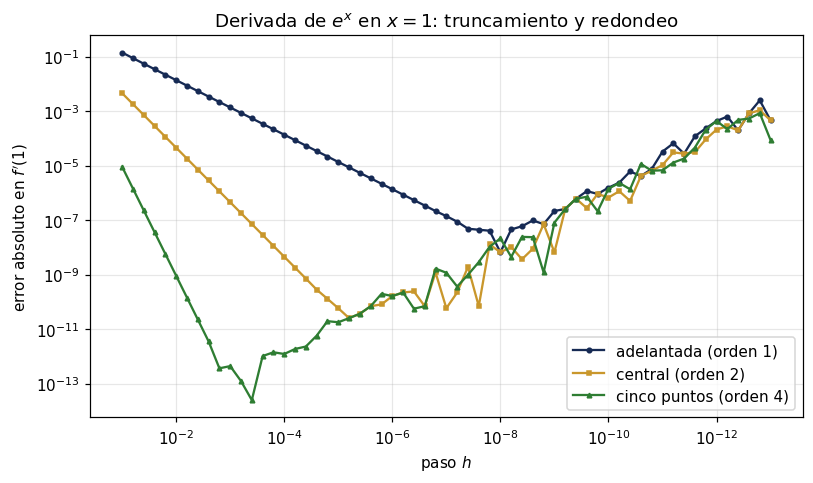

   adelantada: error mínimo 6.6e-09 con h = 1.0e-08;  con h = 1e-12 el error es 4.3e-04
      central: error mínimo 2.5e-11 con h = 6.3e-06;  con h = 1e-12 el error es 2.1e-04
 cinco puntos: error mínimo 2.5e-14 con h = 4.0e-04;  con h = 1e-12 el error es 4.3e-04


In [56]:
pasos = np.logspace(-1, -13, 61)          # de 1e-1 a 1e-13
err_adel = np.abs(adelantada(np.exp, x0, pasos) - exacto)
err_cent = np.abs(central(np.exp, x0, pasos) - exacto)
err_cinco = np.abs(cinco_puntos(np.exp, x0, pasos) - exacto)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.loglog(pasos, err_adel, "o-", ms=3, color=AZUL, label="adelantada (orden 1)")
ax.loglog(pasos, err_cent, "s-", ms=3, color=DORADO, label="central (orden 2)")
ax.loglog(pasos, err_cinco, "^-", ms=3, color=VERDE, label="cinco puntos (orden 4)")
ax.set_xlabel("paso $h$"); ax.set_ylabel("error absoluto en $f'(1)$")
ax.set_title(r"Derivada de $e^x$ en $x = 1$: truncamiento y redondeo")
ax.invert_xaxis(); ax.legend()
plt.tight_layout(); plt.show()

for nombre, err in [("adelantada", err_adel), ("central", err_cent), ("cinco puntos", err_cinco)]:
    i = np.argmin(err)
    print(f"{nombre:>13}: error mínimo {err[i]:.1e} con h = {pasos[i]:.1e};"
          f"  con h = 1e-12 el error es {err[np.argmin(np.abs(pasos - 1e-12))]:.1e}")

La gráfica se lee de izquierda a derecha, con $h$ decreciente. Mientras domina el truncamiento, cada curva baja con la pendiente de su orden. Pasado el óptimo, domina el redondeo y las tres curvas suben juntas con pendiente $-1$, sin importar el orden de la fórmula.

<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**Evite** elegir "el $h$ más pequeño posible". Con $h = 10^{-12}$ las tres fórmulas dan errores del orden de $10^{-4}$, peores que la fórmula adelantada con $h = 10^{-5}$ ($1.4\times10^{-5}$). Con datos experimentales el problema es peor: el ruido de las medidas cumple el papel de $\varepsilon$ y es muchos órdenes de magnitud mayor.

</div>

### 4.4 Derivadas sobre datos tabulados

Con datos tabulados el paso es el de la tabla y no se puede reducir. Sobre un arreglo `f` de $n$ valores con paso $h$, la fórmula central se aplica a todos los puntos interiores a la vez con rebanadas: `(f[2:] - f[:-2])/(2*h)` da $n - 2$ derivadas. En el primer punto no existe $f(x - h)$ y en el último no existe $f(x + h)$: ahí solo se pueden usar la adelantada y la atrasada, de menor orden.

<div style="border: 2px solid #C9972C; background-color: #FBF6EA; padding: 10px 14px; margin: 8px 0;">

**Ejercicio de calentamiento 2 (no calificado): derivadas en una tabla de cinco puntos**

La celda siguiente tiene la tabla de $f(x) = \ln(\tan x)$ en $x = 1.00, 1.05, 1.10, 1.15, 1.20$ (paso $h = 0.05$).

1. Obtenga el arreglo `derivada` con la mejor fórmula disponible en cada punto: adelantada en el primero, atrasada en el último y central en los interiores. Use rebanadas, sin ciclo `for`.
2. Explique por qué el error de los extremos es diez veces mayor que el de los interiores.

**Debe obtener** los errores relativos: $2.54\,\%$ ($x = 1.00$), $0.28\,\%$, $0.35\,\%$, $0.44\,\%$ e $4.94\,\%$ ($x = 1.20$).

</div>

In [57]:
# Tabla del Ejercicio 2
h = 0.05
x_tab = np.array([1.00, 1.05, 1.10, 1.15, 1.20])
f_tab = np.log(np.tan(x_tab))
exacta = 1/(np.sin(x_tab)*np.cos(x_tab))     # derivada analítica, solo para comparar

# TODO: obtenga la derivada en los cinco puntos (sección 4.4), con rebanadas
derivada = np.full(5, -1.0)

print("    x      derivada     exacta    error rel.")
for xi, d, e in zip(x_tab, derivada, exacta):
    print(f"{xi:6.2f} {d:12.6f} {e:10.6f} {100*abs(d - e)/e:9.2f} %")

    x      derivada     exacta    error rel.
  1.00    -1.000000   2.199500    145.46 %
  1.05    -1.000000   2.316935    143.16 %
  1.10    -1.000000   2.473728    140.42 %
  1.15    -1.000000   2.682025    137.29 %
  1.20    -1.000000   2.960931    133.77 %


## 5. Taller 7: energía disipada y derivadas de un oscilador amortiguado, y el valor de $\pi$

### A. Enunciado y requisitos

Un sensor registra la posición de un oscilador amortiguado:

$$x(t) = e^{-\gamma t}\cos(\omega t),$$

donde $x$ es la posición [m] (amplitud inicial 1 m), $t$ el tiempo [s], $\gamma = 0.5\ \text{s}^{-1}$ el coeficiente de amortiguamiento, que fija la rapidez con que decae la amplitud, y $\omega = 2\pi\ \text{rad/s}$ la frecuencia angular de oscilación (periodo de 1 s). Esta posición es solución de la ecuación del oscilador amortiguado

$$\ddot{x} + 2\gamma\,\dot{x} + \omega_0^2\,x = 0, \qquad \omega_0^2 = \omega^2 + \gamma^2,$$

donde $2\gamma\dot{x}$ es la fuerza de fricción por unidad de masa, proporcional a la velocidad, y $\omega_0$ es la frecuencia natural del oscilador sin amortiguamiento. La velocidad y la aceleración exactas son

$$v(t) = -e^{-\gamma t}\left[\gamma\cos(\omega t) + \omega\sin(\omega t)\right], \qquad a(t) = e^{-\gamma t}\left[(\gamma^2 - \omega^2)\cos(\omega t) + 2\gamma\omega\sin(\omega t)\right].$$

**Energía disipada.** La energía mecánica por unidad de masa [J/kg] es

$$E(t) = \underbrace{\tfrac{1}{2}v^2}_{\text{cinética}} + \underbrace{\tfrac{1}{2}\omega_0^2 x^2}_{\text{potencial elástica}} .$$

Derivando y usando la ecuación del oscilador se obtiene $\frac{dE}{dt} = -2\gamma v^2$: la fricción extrae energía a un ritmo $2\gamma v^2$. Integrando entre $0$ y $T$,

$$E_{\text{dis}} = \int_0^T 2\gamma\,v(t)^2\,dt = E(0) - E(T),$$

donde $E_{\text{dis}}$ es la energía disipada por la fricción en el intervalo $[0, T]$. El lado derecho se calcula directamente con $x$ y $v$ en los dos extremos; el lado izquierdo requiere una integral numérica. Que coincidan es una prueba de la conservación de la energía.

**El taller tiene tres partes:**

| Parte | Lenguaje | Qué se hace |
|---|---|---|
| B | Fortran | Módulo de integración de Romberg; energía disipada en $T = 3$ s |
| C | Python | Velocidad y aceleración a partir de las posiciones, con varias fórmulas, comparadas con las exactas |
| D | Fortran | El mismo módulo de Romberg aplicado a $\pi = \int_0^1 \frac{4}{1+x^2}\,dx$, comparado con Monte Carlo (Taller 5) |

**Requisitos generales**

1. Todo el trabajo se guarda en una carpeta llamada `taller_oscilador_romberg`, con los nombres de archivo que se indican en cada parte.
2. Se usa doble precisión: `real(dp)` en Fortran y `float` (64 bits) en Python.
3. La tabla de Romberg se almacena en un arreglo `allocatable` de dos dimensiones con índices desde 0.
4. Las derivadas se calculan sobre el arreglo completo con rebanadas, sin ciclos `for` sobre los puntos.
5. Se entrega el pseudocódigo marco de la Parte B con sus tres espacios completos.

<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**No está permitido** usar `np.gradient`, `np.trapz`, `np.trapezoid`, `scipy.integrate` ni ninguna función de biblioteca que integre o derive. Las fórmulas se programan a partir de las secciones 3 y 4. Cada estudiante sustentará su programa.

</div>

**Pseudocódigo marco de la integración de Romberg** (se entrega con los espacios completos)

```
ENTRADAS: a, b, tol, kmax
h      ← b − a          (Δx: un solo subintervalo en el nivel 0)
S(0,0) ← (h/2)·[ f(a) + f(b) ]
n_eval ← 2
PARA k = 1, 2, ..., kmax:
    h ← h/2
    suma ← [ ESPACIO 1: suma de f en los puntos nuevos del nivel k ]
    n_eval ← n_eval + [ ESPACIO 2: número de puntos nuevos del nivel k ]
    S(k,0) ← S(k−1,0)/2 + h·suma
    PARA j = 1, ..., k:
        S(k,j) ← [ ESPACIO 3: extrapolación de Richardson ]
    FIN PARA
    SI |S(k,k) − S(k−1,k−1)| < tol: TERMINAR con k_final = k
FIN PARA
SALIDAS: tabla S, k_final, n_eval
```

In [58]:
%mkdir -p taller_oscilador_romberg
%cd taller_oscilador_romberg

/content/taller_oscilador_romberg/taller_oscilador_romberg


### B. Parte Fortran: energía disipada con integración de Romberg

**Actividades**

1. Complete el pseudocódigo marco. Los tres espacios se deducen de la sección 3.4 y de su nota sobre el refinamiento del trapecio.
2. Escriba el módulo `modulo_romberg.f90` con la integración de Romberg y los integrandos, y el programa `programa_energia.f90` que lo usa. La organización en procedimientos es decisión suya; debe respetar las reglas de la Semana 6 (`intent` en todos los argumentos, procedimientos en el módulo). El mismo módulo se usará sin cambios en la Parte D.
3. Calcule $E_{\text{dis}}$ en $[0, 3]$ s con tolerancia $10^{-6}$ y el criterio de parada de la diagonal, contando las evaluaciones del integrando.
4. Calcule $E(0) - E(T)$ con las fórmulas de $x$ y $v$, y compárelo con $E_{\text{dis}}$.
5. Escriba la tabla en `tabla_energia.dat` y el resultado en `resultado_energia.dat`. Compile con `-fcheck=bounds`.

**Qué preparar**

| Archivo | Contenido |
|---|---|
| `modulo_romberg.f90` | Integración de Romberg con conteo de evaluaciones; integrandos $2\gamma v^2$ (Parte B) y $4/(1+x^2)$ (Parte D) |
| `programa_energia.f90` | Usa el módulo; escribe los dos archivos `.dat` de esta parte |
| `tabla_energia.dat` | Una fila por nivel $k = 0, \dots, k_{\text{final}}$, con $S_{k,0}, \dots, S_{k,k}$ |
| `resultado_energia.dat` | Una línea: $k_{\text{final}}$, número de evaluaciones, $E_{\text{dis}}$ (Romberg), $E(0) - E(T)$, diferencia absoluta |

<div style="border-left: 5px solid #2E7D32; background-color: #EAF5EA; padding: 10px 14px; margin: 8px 0;">

**Consejo.** Pasar una función como argumento de otra requiere bloques `interface`, que se ven en el Capítulo 4. Por ahora, el módulo puede contener los dos integrandos y una función que elija entre ellos según un argumento entero; así la integración de Romberg se escribe una sola vez y sirve para las Partes B y D.

</div>

<div style="border-left: 5px solid #2E7D32; background-color: #EAF5EA; padding: 10px 14px; margin: 8px 0;">

**Consejo.** Cuente las evaluaciones del integrando dentro del procedimiento que lo llama, no a mano. La tabla hasta el nivel $k$ debe usar exactamente $2^k + 1$ evaluaciones; si su programa reporta más, está evaluando la función dos veces en algunos puntos: revise el espacio 1 del pseudocódigo.

</div>

In [59]:
%%writefile modulo_romberg.f90
module modulo_romberg
    implicit none
    integer, parameter :: dp = kind(1.0d0)

contains

    real(dp) function f_energia(t) result(f)
        real(dp), intent(in) :: t
        real(dp) :: gamma, omega, v
        gamma = 0.5_dp
        omega = 2.0_dp * 4.0_dp * atan(1.0_dp)
        v = -exp(-gamma * t) * (gamma * cos(omega * t) + omega * sin(omega * t))
        f = 2.0_dp * gamma * v**2
    end function f_energia

    real(dp) function f_pi(x) result(f)
        real(dp), intent(in) :: x
        f = 4.0_dp / (1.0_dp + x**2)
    end function f_pi

    real(dp) function f_integrando(x, opcion) result(f)
        real(dp), intent(in) :: x
        integer, intent(in) :: opcion
        if (opcion == 1) then
            f = f_energia(x)
        else if (opcion == 2) then
            f = f_pi(x)
        else
            f = 0.0_dp
        end if
    end function f_integrando

    subroutine romberg(a, b, tol, kmax, opcion, S, k_final, n_eval)
        real(dp), intent(in) :: a, b, tol
        integer, intent(in) :: kmax, opcion
        real(dp), allocatable, intent(out) :: S(:,:)
        integer, intent(out) :: k_final, n_eval

        real(dp) :: h, suma
        integer :: k, i, j, puntos_nuevos

        if (allocated(S)) deallocate(S)
        allocate(S(0:kmax, 0:kmax))
        S = 0.0_dp

        h = b - a
        S(0,0) = (h / 2.0_dp) * (f_integrando(a, opcion) + f_integrando(b, opcion))
        n_eval = 2

        do k = 1, kmax
            h = h / 2.0_dp
            puntos_nuevos = 2**(k-1)
            suma = 0.0_dp

            do i = 1, puntos_nuevos
                suma = suma + f_integrando(a + real(2*i - 1, dp) * h, opcion)
            end do

            n_eval = n_eval + puntos_nuevos
            S(k,0) = S(k-1,0) / 2.0_dp + h * suma

            do j = 1, k
                S(k,j) = S(k,j-1) + (S(k,j-1) - S(k-1,j-1)) / (4.0_dp**j - 1.0_dp)
            end do

            if (abs(S(k,k) - S(k-1,k-1)) < tol) then
                k_final = k
                return
            end if
        end do
        k_final = kmax
    end subroutine romberg

end module modulo_romberg

Writing modulo_romberg.f90


In [60]:
%%writefile programa_energia.f90
program programa_energia
    use modulo_romberg
    implicit none

    real(dp) :: a, b, tol
    integer :: kmax, k_final, n_eval
    real(dp), allocatable :: S(:,:)
    real(dp) :: e_dis, e_ref, diff
    real(dp) :: gamma, omega, w0_sq, x0, v0, xT, vT, E0, ET
    integer :: k, j

    a = 0.0_dp
    b = 3.0_dp
    tol = 1.0e-6_dp
    kmax = 20

    gamma = 0.5_dp
    omega = 2.0_dp * 4.0_dp * atan(1.0_dp)
    w0_sq = omega**2 + gamma**2

    call romberg(a, b, tol, kmax, 1, S, k_final, n_eval)
    e_dis = S(k_final, k_final)

    x0 = exp(-gamma * a) * cos(omega * a)
    v0 = -exp(-gamma * a) * (gamma * cos(omega * a) + omega * sin(omega * a))
    E0 = 0.5_dp * v0**2 + 0.5_dp * w0_sq * x0**2

    xT = exp(-gamma * b) * cos(omega * b)
    vT = -exp(-gamma * b) * (gamma * cos(omega * b) + omega * sin(omega * b))
    ET = 0.5_dp * vT**2 + 0.5_dp * w0_sq * xT**2

    e_ref = E0 - ET
    diff = abs(e_dis - e_ref)

    open(unit=10, file='tabla_energia.dat', status='replace')
    do k = 0, k_final
        write(10, *) (S(k,j), j=0, k)
    end do
    close(10)

    open(unit=20, file='resultado_energia.dat', status='replace')
    write(20, *) k_final, n_eval, e_dis, e_ref, diff
    close(20)

end program programa_energia

Writing programa_energia.f90


In [61]:
# Compila y ejecuta la Parte B (ejecute esta celda cuando sus archivos estén listos)
!gfortran -fcheck=bounds -o programa_energia modulo_romberg.f90 programa_energia.f90 && ./programa_energia

### C. Parte Python: velocidad y aceleración a partir de las posiciones

**Actividades**

1. Escriba `derivadas_oscilador.py`. Construya el arreglo de tiempos en $[0, 3]$ s con paso $\Delta t$ y el arreglo de posiciones $x(t)$.
2. Obtenga la velocidad con las cuatro fórmulas de la sección 4.1 (adelantada, atrasada, central y cinco puntos) y la aceleración con la fórmula central de la sección 4.2. Cada fórmula se evalúa solo en los puntos donde está definida: por ejemplo, la central no existe en el primer ni en el último punto.
3. Con $\Delta t = 0.01$ s, escriba `derivadas_oscilador.dat` con cuatro columnas ($t$, $x$, $v$ central, $a$ central) en los puntos donde la fórmula central está definida, y grafique $v$ y $a$ numéricas junto con las exactas en `derivadas_oscilador.png`.
4. Para $\Delta t = 0.01$ s y $\Delta t = 0.005$ s, obtenga el error máximo de cada fórmula frente a la derivada exacta. Escriba `errores_derivadas.dat` con dos filas y seis columnas: $\Delta t$, error de la adelantada, de la atrasada, de la central y de cinco puntos para $v$, y error de la central para $a$.
5. Obtenga la razón entre los errores de los dos pasos para cada fórmula y compárela con la tabla de la sección 4.2.

**Qué preparar**

| Archivo | Contenido |
|---|---|
| `derivadas_oscilador.py` | Construye los datos, deriva con rebanadas, escribe los archivos y la figura |
| `derivadas_oscilador.dat` | $\Delta t = 0.01$ s: $t$, $x$, $v$, $a$ en los 299 puntos interiores |
| `errores_derivadas.dat` | Dos filas ($\Delta t = 0.01, 0.005$): $\Delta t$ y los cinco errores máximos |
| `derivadas_oscilador.png` | $v$ y $a$ numéricas y exactas contra $t$ |

In [62]:
%%writefile derivadas_oscilador.py
import numpy as np
import matplotlib.pyplot as plt

gamma = np.float64(0.5)
omega = np.float64(2.0 * np.pi)
t_fin = np.float64(3.0)

def exact_v(t):
    return -np.exp(-gamma * t) * (gamma * np.cos(omega * t) + omega * np.sin(omega * t))

def exact_a(t):
    return np.exp(-gamma * t) * ((gamma**2 - omega**2) * np.cos(omega * t) + 2.0 * gamma * omega * np.sin(omega * t))

def calcular_derivadas(dt):
    dt = np.float64(dt)
    N = int(np.round(t_fin / dt)) + 1
    t = np.linspace(0.0, t_fin, N, dtype=np.float64)
    x = np.exp(-gamma * t) * np.cos(omega * t)

    v_adelantada = (x[1:] - x[:-1]) / dt
    err_fw = np.max(np.abs(v_adelantada - exact_v(t[:-1])))

    v_atrasada = (x[1:] - x[:-1]) / dt
    err_bw = np.max(np.abs(v_atrasada - exact_v(t[1:])))

    v_central = (x[2:] - x[:-2]) / (2.0 * dt)
    err_cen_v = np.max(np.abs(v_central - exact_v(t[1:-1])))

    v_5puntos = (-x[4:] + 8.0*x[3:-1] - 8.0*x[1:-3] + x[:-4]) / (12.0 * dt)
    err_5p = np.max(np.abs(v_5puntos - exact_v(t[2:-2])))

    a_central = (x[2:] - 2.0*x[1:-1] + x[:-2]) / (dt**2)
    err_cen_a = np.max(np.abs(a_central - exact_a(t[1:-1])))

    return t, x, v_central, a_central, err_fw, err_bw, err_cen_v, err_5p, err_cen_a

t1, x1, v_cen1, a_cen1, e_fw1, e_bw1, e_cv1, e_5p1, e_ca1 = calcular_derivadas(0.01)
_, _, _, _, e_fw2, e_bw2, e_cv2, e_5p2, e_ca2 = calcular_derivadas(0.005)

datos_derivadas = np.column_stack((t1[1:-1], x1[1:-1], v_cen1, a_cen1))
np.savetxt('derivadas_oscilador.dat', datos_derivadas, fmt='%.15e')

datos_errores = np.array([
    [0.01, e_fw1, e_bw1, e_cv1, e_5p1, e_ca1],
    [0.005, e_fw2, e_bw2, e_cv2, e_5p2, e_ca2]
])
np.savetxt('errores_derivadas.dat', datos_errores, fmt='%.15e')

plt.figure(figsize=(10, 6))
t_exact = np.linspace(0, t_fin, 1000)
plt.plot(t_exact, exact_v(t_exact), 'b-', label='$v$ exacta')
plt.plot(t_exact, exact_a(t_exact), 'r-', label='$a$ exacta')
plt.plot(t1[1:-1], v_cen1, 'b--', label='$v$ central (numérica)')
plt.plot(t1[1:-1], a_cen1, 'r--', label='$a$ central (numérica)')
plt.title('Velocidad y Aceleración del Oscilador Amortiguado')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.legend()
plt.grid(True)
plt.savefig('derivadas_oscilador.png', dpi=300)

Writing derivadas_oscilador.py


In [63]:
# Ejecuta la Parte C (ejecute esta celda cuando su archivo esté listo)
!python derivadas_oscilador.py

### D. Parte Fortran: el valor de $\pi$ con el mismo módulo

**Actividades**

1. Escriba `programa_pi.f90`, que use `modulo_romberg.f90` **sin modificarlo** para calcular $\pi = \int_0^1 \frac{4}{1+x^2}\,dx$ con tolerancia $10^{-5}$.
2. Escriba en `resultado_pi.dat` una línea con $k_{\text{final}}$, el número de evaluaciones, el valor obtenido y su error $|S_{k,k} - \pi|$.
3. Con el programa de Monte Carlo de su Taller 5, estime $\pi$ con $N = 10^6$ muestras y anote el error.
4. Con el error estadístico $\sigma/\sqrt{N}$ de Monte Carlo, donde $\sigma = 4\sqrt{p(1-p)}$ y $p = \pi/4$, obtenga cuántas muestras harían falta para un error de $10^{-5}$.
5. Resuma en el reporte una tabla con tres filas (Romberg; Monte Carlo con $10^6$ muestras; Monte Carlo con error $10^{-5}$) y dos columnas (evaluaciones, error).

**Qué preparar**

| Archivo | Contenido |
|---|---|
| `programa_pi.f90` | Usa `modulo_romberg.f90` sin cambios; escribe `resultado_pi.dat` |
| `resultado_pi.dat` | Una línea: $k_{\text{final}}$, evaluaciones, valor de $\pi$, error |

In [64]:
%%writefile programa_pi.f90
program programa_pi
    use modulo_romberg
    implicit none

    real(dp) :: a, b, tol
    integer :: kmax, k_final, n_eval
    real(dp), allocatable :: S(:,:)
    real(dp) :: pi_calc, pi_exact, error_pi

    a = 0.0_dp
    b = 1.0_dp
    tol = 1.0e-5_dp
    kmax = 20

    call romberg(a, b, tol, kmax, 2, S, k_final, n_eval)

    pi_calc = S(k_final, k_final)
    pi_exact = 4.0_dp * atan(1.0_dp)
    error_pi = abs(pi_calc - pi_exact)

    open(unit=30, file='resultado_pi.dat', status='replace')
    write(30, *) k_final, n_eval, pi_calc, error_pi
    close(30)

end program programa_pi

Writing programa_pi.f90


In [65]:
# Compila y ejecuta la Parte D (ejecute esta celda cuando sus archivos estén listos)
!gfortran -fcheck=bounds -o programa_pi modulo_romberg.f90 programa_pi.f90 && ./programa_pi

### E. Preguntas de interpretación y reporte

Responda en el reporte, con los números de sus archivos:

1. **Conservación de la energía.** ¿Qué tan cerca están $E_{\text{dis}}$ y $E(0) - E(T)$? Compare esa diferencia con la tolerancia $10^{-6}$ y explique por qué el criterio de la diagonal es conservador.
2. **Integrando oscilante.** La energía necesitó muchas más evaluaciones que $\pi$. Observe en la tabla de Romberg los primeros niveles (1, 2, 4 y 8 subintervalos en 3 s) y explique por qué el método no puede converger mientras la malla no resuelve las oscilaciones de $v(t)^2$.
3. **Órdenes de las derivadas.** Compare las razones de la Parte C con la tabla de la sección 4.2. ¿Por qué la adelantada y la atrasada tienen errores casi iguales?
4. **Costo.** Con la tabla de la Parte D, ¿cuántas veces más evaluaciones necesita Monte Carlo que Romberg para un error de $10^{-5}$? ¿En qué situaciones sigue siendo preferible Monte Carlo?

**Reporte (una página, plantilla del curso).** Las secciones de contexto físico, método y resultado se refieren al oscilador (Partes B y C). La Parte D puede alimentar la sección de obstáculo o decisión de implementación.

### F. Verificación

La celda siguiente **no debe modificarse**. Lee los archivos que escribieron sus programas, recalcula de forma independiente los valores de referencia, y comprueba que cada archivo es posterior al código que lo genera (un archivo viejo de una versión anterior del programa no cuenta). El taller exige los cuatro PASS.

In [66]:
# ===================== VERIFICACIÓN DEL TALLER 7 (no modificar) =====================
import os
import numpy as np

def actualizado(dat, fuentes):
    """El archivo existe y es posterior a todos los códigos fuente."""
    if not os.path.exists(dat):
        return False, f"no existe {dat}"
    for f in fuentes:
        if not os.path.exists(f):
            return False, f"no existe {f}"
        if os.path.getmtime(dat) < os.path.getmtime(f):
            return False, f"{dat} es anterior a {f}: vuelva a ejecutar el programa"
    return True, ""

G, W = 0.5, 2*np.pi
def x_ex(t): return np.exp(-G*t)*np.cos(W*t)
def v_ex(t): return -np.exp(-G*t)*(G*np.cos(W*t) + W*np.sin(W*t))
def a_ex(t): return np.exp(-G*t)*((G*G - W*W)*np.cos(W*t) + 2*G*W*np.sin(W*t))
def energia(t): return 0.5*v_ex(t)**2 + 0.5*(W*W + G*G)*x_ex(t)**2

resultados = []
def caso(nombre, funcion):
    try:
        ok, detalle = funcion()
    except Exception as e:
        ok, detalle = False, f"error al leer: {e}"
    resultados.append(ok)
    print(f"[{'PASS' if ok else 'FAIL'}] {nombre}" + (f"  -> {detalle}" if detalle else ""))

def c1():
    ok, d = actualizado("resultado_energia.dat", ["modulo_romberg.f90", "programa_energia.f90"])
    if not ok: return ok, d
    k, n, e_dis, e_ref_est, dif = np.loadtxt("resultado_energia.dat")
    e_ref = energia(0.0) - energia(3.0)
    if abs(e_ref_est - e_ref) > 1e-10: return False, f"E(0) - E(T) = {e_ref_est:.10f}, se espera {e_ref:.10f}"
    if abs(e_dis - e_ref) >= 1e-6: return False, f"|E_dis - (E(0) - E(T))| = {abs(e_dis - e_ref):.2e}"
    if int(k) != 8 or int(n) != 257: return False, f"k_final = {int(k)}, evaluaciones = {int(n)} (se esperan 8 y 257)"
    return True, f"E_dis = {e_dis:.10f} J/kg, k = 8, 257 evaluaciones"

def c2():
    ok, d = actualizado("derivadas_oscilador.dat", ["derivadas_oscilador.py"])
    if not ok: return ok, d
    t, x, v, a = np.loadtxt("derivadas_oscilador.dat", unpack=True)
    if t.size != 299 or abs(t[1] - t[0] - 0.01) > 1e-12: return False, "se esperan 299 puntos interiores con dt = 0.01"
    if np.max(np.abs(x - x_ex(t))) > 1e-12: return False, "las posiciones no corresponden al oscilador"
    ev, ea = np.abs(v - v_ex(t)).max(), np.abs(a - a_ex(t)).max()
    if not (0.9*3.765e-3 <= ev <= 1.1*3.765e-3): return False, f"error de v = {ev:.3e}"
    if not (0.9*1.215e-2 <= ea <= 1.1*1.215e-2): return False, f"error de a = {ea:.3e}"
    return True, f"errores máximos v {ev:.3e}, a {ea:.3e}"

def c3():
    ok, d = actualizado("errores_derivadas.dat", ["derivadas_oscilador.py"])
    if not ok: return ok, d
    e = np.loadtxt("errores_derivadas.dat")
    if e.shape != (2, 6): return False, f"forma {e.shape}, se espera (2, 6)"
    if abs(e[0, 4] - 3.0275e-6)/3.0275e-6 > 0.1: return False, f"error de cinco puntos con dt = 0.01: {e[0,4]:.3e}"
    r = e[0, 1:]/e[1, 1:]
    rangos = [(1.9, 2.1), (1.9, 2.1), (3.8, 4.2), (15.0, 17.0), (3.7, 4.2)]
    if not all(lo <= ri <= hi for ri, (lo, hi) in zip(r, rangos)):
        return False, "razones " + ", ".join(f"{ri:.2f}" for ri in r)
    return True, "razones " + ", ".join(f"{ri:.2f}" for ri in r)

def c4():
    ok, d = actualizado("resultado_pi.dat", ["modulo_romberg.f90", "programa_pi.f90"])
    if not ok: return ok, d
    k, n, r, e = np.loadtxt("resultado_pi.dat")
    if abs(r - np.pi) >= 1e-5: return False, f"|R - pi| = {abs(r - np.pi):.2e}"
    if int(k) != 4 or int(n) != 17: return False, f"k_final = {int(k)}, evaluaciones = {int(n)} (se esperan 4 y 17)"
    return True, f"pi = {r:.10f}, k = 4, 17 evaluaciones"

caso("1. Energía disipada: Romberg con tol 1e-6 coincide con E(0) - E(T)", c1)
caso("2. Velocidad y aceleración centrales con dt = 0.01", c2)
caso("3. Órdenes de las cinco fórmulas de derivación", c3)
caso("4. pi con el mismo módulo: tol 1e-5, 17 evaluaciones", c4)
print(f"\nResultado: {sum(resultados)} de {len(resultados)} PASS")

[PASS] 1. Energía disipada: Romberg con tol 1e-6 coincide con E(0) - E(T)  -> E_dis = 18.9940046974 J/kg, k = 8, 257 evaluaciones
[PASS] 2. Velocidad y aceleración centrales con dt = 0.01  -> errores máximos v 3.765e-03, a 1.215e-02
[PASS] 3. Órdenes de las cinco fórmulas de derivación  -> razones 1.99, 1.99, 4.00, 15.99, 3.94
[PASS] 4. pi con el mismo módulo: tol 1e-5, 17 evaluaciones  -> pi = 3.1415926653, k = 4, 17 evaluaciones

Resultado: 4 de 4 PASS
